# TP – Analisando Grafos do SNAP · G13 `soc-RedditHyperlinks`

Teoria dos Grafos – IC/UFBA · Prof. Bruno Pereira dos Santos · Matrícula **224216276**

Rede de hiperlinks entre subreddits do Reddit (SNAP; Kumar et al., 2018), arquivo `soc-redditHyperlinks-body.tsv`.

Toda a lógica está em `src/` (algoritmos, métricas, distâncias, centralidades, modelos, medição, tabelas e figuras);
este notebook só orquestra os experimentos e mostra os resultados. As implementações são testadas contra o
networkx em `tests/` (`python -m pytest`).

Para rodar do zero: `python data/raw/download.py` e depois *Kernel → Restart & Run All* (~40 min).

## 0. Configuração e determinação do grafo

In [1]:
import sys, os, platform, random, time, math, subprocess
from pathlib import Path
import numpy as np, pandas as pd, networkx as nx

sys.path.insert(0, str(Path.cwd()))
from src import (tratamento as T, algoritmos as A, metricas as M, distancias as D,
                 centralidade as Ce, robustez as R, medicao as Me, analise as An, figuras as F)
from src.relatorio import salvar_tabela
from src.analise import br, pct

SEED = 224216276
CONFERIR_IGRAPH = True      # confere distâncias e betweenness com o igraph (opcional)
random.seed(SEED); np.random.seed(SEED % 2**32)
RAW, PROC = Path("data/raw/soc-redditHyperlinks-body.tsv"), Path("data/processed")
PROC.mkdir(parents=True, exist_ok=True)
F.estilo()

print("Python", platform.python_version(), "|", platform.platform())
print("CPU:", platform.processor() or platform.machine(), "| núcleos:", os.cpu_count())
print("networkx", nx.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

Python 3.13.18 | Linux-6.18.44-fc-v726-x86_64-with-glibc2.39
CPU: x86_64 | núcleos: 2
networkx 3.7 | pandas 3.0.5 | numpy 2.5.3


**Regra de mapeamento:** $f(M) = ((\text{soma dos dígitos de } M) \times (\text{últimos 2 dígitos de } M + 1)) \bmod 129$; se 0, usar 129.

In [2]:
assert An.indice_grafo(225216327, False) == 66 and An.indice_grafo(2025000078, False) == 90  # exemplos do enunciado
G_ID = An.indice_grafo(224216276)
print(f"→ Grafo G{G_ID}: soc-RedditHyperlinks (Social networks)")

soma dos dígitos = 32; últimos 2 dígitos = 76
(32 × 77) mod 129 = 2464 mod 129 = 13
→ Grafo G13: soc-RedditHyperlinks (Social networks)


> Na planilha ANALISANDO-SNAP-DATASET o mesmo dataset aparece como G13 (Social networks), G72 (Signed), G92 (Temporal) e G109 (Online communities). Usamos a entrada G13.

### Testes automatizados das implementações

In [3]:
r = subprocess.run([sys.executable, "-m", "pytest", "tests", "--color=no", "-p", "no:cacheprovider"],
                   capture_output=True, text=True)
print([l for l in r.stdout.splitlines() if "passed" in l or "failed" in l][-1])
assert r.returncode == 0, r.stdout

44 passed in 2.70s


## 1. Carga e descrição do grafo original

In [4]:
df = T.carregar_bruto(RAW)
salvar_tabela(pd.Series(T.descrever_bruto(df), name="valor").to_frame(), "01_dados_originais",
              "Descrição do arquivo original soc-redditHyperlinks-body.tsv.")

,valor
posts (linhas),286561
subreddits distintos,35776
pares dirigidos distintos,137821
posts por par (média),2.079
posts por par (máximo),548
links positivos (+1),265491
links negativos (-1),21070
auto-loops,0
início,2013-12-31 16:39:58
fim,2017-04-30 16:58:21


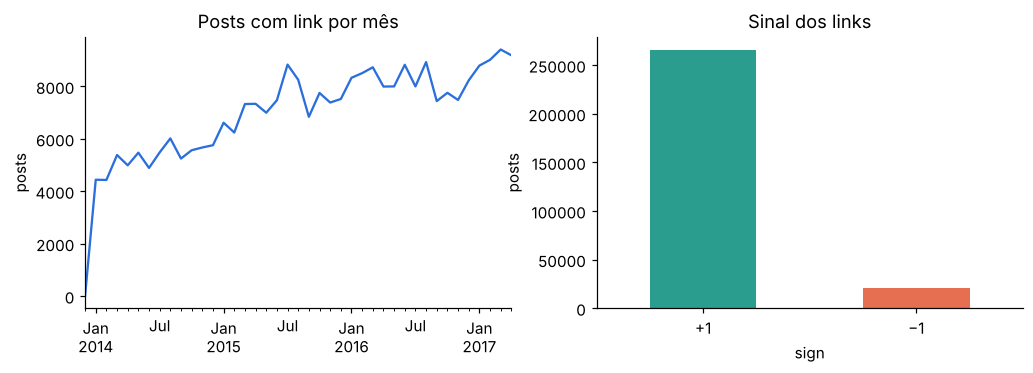

In [5]:
F.original(df);

A planilha informa 55.863 vértices e 858.490 arestas porque descreve o dataset completo (arquivos *body* + *title*). Aqui usamos apenas o *body*.

## 2. Tratamento dos dados

In [6]:
e_dir = T.arestas_dirigidas(df)
e_und = T.arestas_nao_dirigidas(e_dir)
e_dir.to_csv(PROC / "arestas_dirigidas.csv", index=False)
e_und.to_csv(PROC / "arestas_nao_dirigidas.csv", index=False)
G_dir, G_und = T.grafo_dirigido(e_dir), T.grafo_nao_dirigido(e_und)
G_lcc = T.maior_componente(G_und)
nx.write_edgelist(G_lcc, PROC / "maior_componente.edgelist.gz", data=["count", "sign", "weight"])
adj, adj_lcc = A.lista_adj(G_und), A.lista_adj(G_lcc)
succ = {u: list(G_dir.successors(u)) for u in G_dir}
pred = {u: list(G_dir.predecessors(u)) for u in G_dir}
n_, m_ = G_lcc.number_of_nodes(), G_lcc.number_of_edges()
salvar_tabela(An.tabela_tratamentos(df, e_dir, e_und, G_lcc), "02_tratamentos", "Tratamentos aplicados aos dados.")

,Descrição,Resultado
Tratamento,,
Temporal → estático,União de todos os posts de 31/12/2013 a 30/04/...,286.561 posts
Remoção de auto-loops,Verificado: o arquivo não tem auto-loops,0 removidos
Multigrafo → simples (dirigido),Uma aresta por par (u→v); count = nº de posts;...,137.821 arestas
Dirigido → não dirigido,Junta u→v e v→u; count somado; sign pelo saldo...,124.330 arestas
Pesos,w = 1/count (pares com mais links ficam mais p...,"Dijkstra, Bellman-Ford, Floyd-Warshall, AGM"
Maior componente conexa,"Usada em distâncias, small-world e robustez",34.671 vértices / 123.570 arestas
Subgrafos de teste,Subgrafos induzidos conexos por BFS (n = 100 a...,Floyd-Warshall e curvas de tempo
Atributos descartados,Vetor PROPERTIES (86 atributos de texto) e POS...,economia de memória


## 3. Parte I – Análise estrutural obrigatória

Medidas no grafo não dirigido completo; diâmetro, raio e caminho médio na maior componente (infinitos num grafo desconexo), calculados **exatamente** por BFS própria a partir de todos os vértices.

In [7]:
rg = M.resumo_graus(adj)
comps = A.componentes_conexas(adj)
clust = M.clusterizacao(adj)
t0 = time.perf_counter()
dist = D.distancias_exatas(adj_lcc)              # paraleliza entre os núcleos disponíveis
t_dist = time.perf_counter() - t0
print(f"diâmetro={dist['diametro']}  raio={dist['raio']}  L={dist['caminho_medio']:.4f}  "
      f"({n_} BFS em {t_dist:.0f} s)")

diâmetro=11  raio=6  L=3.9136  (34671 BFS em 243 s)


In [8]:
if CONFERIR_IGRAPH:
    import igraph as ig
    g_lcc = ig.Graph.from_networkx(G_lcc)
    assert g_lcc.diameter() == dist["diametro"] and int(min(g_lcc.eccentricity())) == dist["raio"]
    assert math.isclose(g_lcc.average_path_length(), dist["caminho_medio"], rel_tol=1e-12)
    print("Distâncias conferem com o igraph.")

Distâncias conferem com o igraph.


In [9]:
tam = pd.Series([len(c) for c in comps]).value_counts().sort_index(ascending=False)
salvar_tabela(tam.rename_axis("tamanho").rename("quantidade de componentes").to_frame(),
              "03_tamanho_componentes", "Tamanho das componentes conexas do grafo não dirigido.")
salvar_tabela(An.tabela_parte1(rg, comps, dist, clust), "03_parte1_medidas",
              "Parte I: medidas estruturais do G13 e indicação do que foi calculado.")

,Valor,Grafo,Calculado?
Medida,,,
Número de vértices,35776,G_und,sim
Número de arestas,124330,G_und,sim
Grau mínimo,1,G_und,sim
Grau máximo,2336,G_und,sim
Grau médio,6.9505,G_und,sim
Distribuição de graus,figura 03,G_und,sim
Densidade,0.000194,G_und,sim
Número de componentes conexas,497,G_und,sim
Tamanho de cada componente,tabela 03,G_und,sim


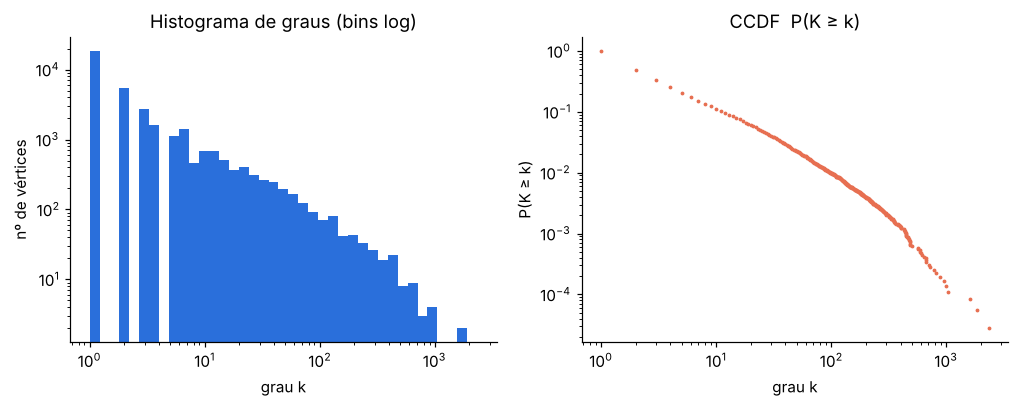

In [10]:
F.distribuicao_graus(adj);

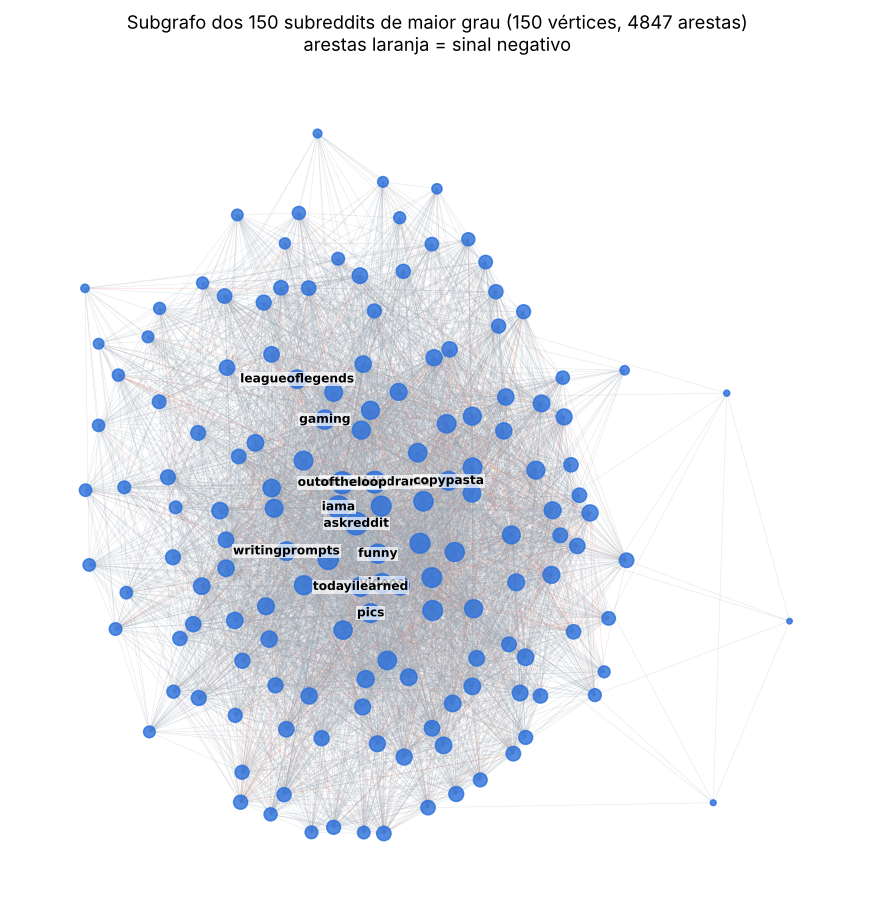

In [11]:
F.visualizacao(G_und);

## 4. Parte II – Algoritmos da disciplina

### 4.1 Resultados no grafo

In [12]:
s_hub = max(G_lcc.degree, key=lambda x: x[1])[0]
awL, eL = A.lista_adj_ponderada(G_lcc), A.lista_arestas(G_lcc)
d_bfs, ordem_dfs = A.bfs(adj_lcc, s_hub), A.dfs(adj_lcc, s_hub)
eul_u, eul_d = A.euleriano_nao_dirigido(adj), A.euleriano_dirigido(succ, pred)
d_dij = A.dijkstra(awL, s_hub)
d_bf, neg_bf, it_bf = A.bellman_ford(list(G_lcc), eL, s_hub, dirigido=False)
agm_k, peso_k = A.kruskal(list(G_lcc), eL)
agm_p, peso_p = A.prim(awL)
scc = A.tarjan_scc(succ)
pontes, artic = A.pontes_articulacoes(adj_lcc)
wcc = A.componentes_conexas({u: list(set(succ[u]) | set(pred[u])) for u in succ})
iters_bf = [A.bellman_ford(list(G_lcc), eL, s, dirigido=False)[2] for s in random.Random(1).sample(list(G_lcc), 10)]

res_alg = pd.DataFrame([
    ["BFS", f"origem = {s_hub}; alcança {br(len(d_bfs))} vértices; excentricidade = {max(d_bfs.values())}"],
    ["DFS", f"origem = {s_hub}; visita {br(len(ordem_dfs))} vértices"],
    ["Euler (não dirigido)", f"{br(eul_u['vertices_grau_impar'])} vértices de grau ímpar; conexo: {br(eul_u['conexo'])}; euleriano: {br(eul_u['euleriano'])}; semieuleriano: {br(eul_u['semi_euleriano'])}"],
    ["Euler (dirigido)", f"{br(eul_d['vertices_desbalanceados'])} vértices com entrada ≠ saída; fracamente conexo: {br(eul_d['fracamente_conexo'])}; euleriano: {br(eul_d['euleriano'])}"],
    ["Dijkstra", f"w = 1/count; maior distância a partir de {s_hub} = {br(max(d_dij.values()))}"],
    ["Bellman-Ford", f"mesmas distâncias que Dijkstra: {br(all(math.isclose(d_bf[k], d_dij[k]) for k in d_dij))}; rodadas até convergir: {it_bf} (10 origens: {min(iters_bf)}–{max(iters_bf)}); ciclo negativo: {br(neg_bf)}"],
    ["Floyd-Warshall", "só em subgrafos (n ≤ 2000): O(n³) e matriz 34.671² ≈ 1,2·10⁹ células (~9,6 GB) inviáveis"],
    ["Tarjan (SCC)", f"{br(len(scc))} componentes fortemente conexas; maior = {br(len(scc[0]))} vértices ({pct(len(scc[0]) / G_dir.number_of_nodes())}); {br(sum(len(c) == 1 for c in scc))} unitárias; {len(wcc)} fracamente conexas"],
    ["Tarjan (pontes e articulações)", f"maior componente: {br(len(pontes))} pontes ({pct(len(pontes) / m_)} das arestas) e {br(len(artic))} vértices de articulação ({pct(len(artic) / n_)})"],
    ["Kruskal", f"{br(len(agm_k))} arestas; peso total = {br(peso_k, 8)}"],
    ["Prim", f"{br(len(agm_p))} arestas; peso total = {br(peso_p, 8)} (igual ao Kruskal: {br(math.isclose(peso_k, peso_p))})"],
], columns=["Algoritmo", "Resultado"]).set_index("Algoritmo")
salvar_tabela(res_alg, "04_resultados_algoritmos", "Resultados dos algoritmos da Parte II no G13.")

,Resultado
Algoritmo,
BFS,origem = askreddit; alcança 34.671 vértices; e...
DFS,origem = askreddit; visita 34.671 vértices
Euler (não dirigido),25.306 vértices de grau ímpar; conexo: não; eu...
Euler (dirigido),32.257 vértices com entrada ≠ saída; fracament...
Dijkstra,w = 1/count; maior distância a partir de askre...
Bellman-Ford,mesmas distâncias que Dijkstra: sim; rodadas a...
Floyd-Warshall,só em subgrafos (n ≤ 2000): O(n³) e matriz 34....
Tarjan (SCC),24.071 componentes fortemente conexas; maior =...
Tarjan (pontes e articulações),"maior componente: 18.057 pontes (14,6% das are..."


**Bellman-Ford com o sinal como peso.** No grafo **dirigido**, usando o sinal real dos links como peso (−1 para links negativos), o algoritmo encontra ciclos negativos – ciclos de hostilidade líquida entre comunidades. Com ciclos negativos não há caminho mínimo bem definido: é o caso em que Bellman-Ford é aplicável e Dijkstra não.

In [13]:
Sd = G_dir.subgraph(T.subgrafo_bfs(G_lcc, 2000, raiz=s_hub, seed=SEED)).copy()
arest_sinal = [(u, v, float(d["sign"])) for u, v, d in Sd.edges(data=True)]
_, neg_sinal, it_sinal = A.bellman_ford(list(Sd), arest_sinal, s_hub, dirigido=True)
print(f"Subgrafo dirigido: {Sd.number_of_nodes()} vértices, {Sd.number_of_edges()} arestas "
      f"({sum(w < 0 for *_, w in arest_sinal)} negativas) → ciclo negativo = {neg_sinal}")

Subgrafo dirigido: 2000 vértices, 28460 arestas (2333 negativas) → ciclo negativo = True


### 4.2 Tempo de execução no grafo completo (30 repetições)
Uma execução de aquecimento descartada e coletor de lixo desligado em cada cronometragem. Com $n = 30$ usamos a Normal:
$\bar{x} \pm z_{\alpha/2}\,s/\sqrt{n}$, $z_{0{,}025} = 1{,}96$. Origens sorteadas a cada repetição.

In [14]:
fontes = random.Random(SEED).sample(list(G_lcc), 30)
subs_fw = {n: T.subgrafo_bfs(G_lcc, n, seed=SEED + n) for n in (100, 250, 500, 1000)}
linhas = []
for nome, cx, grafo, f, ent in An.casos_tempo(G_lcc, G_dir, adj, adj_lcc, succ, pred, subs_fw, fontes):
    r = Me.medir(f, ent, reps=30)
    linhas.append({"Algoritmo": nome, "Complexidade": cx, "Grafo": grafo, **r})
    print(f"{nome:28s} {r['media_s'] * 1e3:10.2f} ms ± {r['desvio_s'] * 1e3:.2f}")
tempos = pd.DataFrame(linhas).set_index("Algoritmo").drop(columns=["valor_critico"])
salvar_tabela(tempos, "04_tempos_execucao",
              "Tempo de execução (s): média, desvio padrão e IC de 95\\% (30 repetições, Normal).")

BFS                               32.94 ms ± 1.67


DFS                               30.81 ms ± 1.53


Euler (não dirigido)              51.48 ms ± 10.19


Euler (dirigido)                 112.27 ms ± 7.22


Dijkstra                         134.09 ms ± 12.11


Bellman-Ford                     409.13 ms ± 58.86


... (8 outputs left out)

Floyd-Warshall puro (n=100)       27.83 ms ± 1.83


Floyd-Warshall puro (n=250)      147.26 ms ± 11.40


Floyd-Warshall puro (n=500)     4677.29 ms ± 227.17


,Complexidade,Grafo,n,media_s,desvio_s,ic_inf_s,ic_sup_s,distribuicao
Algoritmo,,,,,,,,
BFS,O(n + m),maior componente,30,0.032944,0.001672,0.032346,0.033542,Normal (z)
DFS,O(n + m),maior componente,30,0.030815,0.001530,0.030268,0.031362,Normal (z)
Euler (não dirigido),O(n + m),G_und,30,0.051481,0.010192,0.047834,0.055128,Normal (z)
Euler (dirigido),O(n + m),G_dir,30,0.112268,0.007221,0.109684,0.114852,Normal (z)
Dijkstra,O((n + m) log n),maior componente,30,0.134088,0.012108,0.129755,0.138420,Normal (z)
Bellman-Ford,O(n · m),maior componente,30,0.409128,0.058865,0.388064,0.430192,Normal (z)
Tarjan (SCC),O(n + m),G_dir,30,0.065839,0.003956,0.064423,0.067255,Normal (z)
Tarjan (pontes e articulações),O(n + m),maior componente,30,0.076629,0.006794,0.074199,0.079060,Normal (z)
Kruskal,O(m log m),maior componente,30,0.104310,0.011608,0.100156,0.108464,Normal (z)


### 4.3 Complexidade observada × teórica
Subgrafos conexos de tamanho crescente; 10 repetições por tamanho (IC com t-Student, $n < 30$) e ajuste $t \approx c \cdot f(n, m)$ por mínimos quadrados. Floyd-Warshall em subgrafos menores (5 repetições).

In [15]:
tamanhos = [1000, 2000, 4000, 8000, 16000]
grafos = [T.subgrafo_bfs(G_lcc, n, seed=SEED) for n in tamanhos] + [G_lcc]
esc = Me.escala(An.casos_escala(G_dir), grafos, reps=10)
grafos_fw = [T.subgrafo_bfs(G_lcc, n, seed=SEED + n) for n in (100, 250, 500, 1000, 2000)]
esc_fw = Me.escala({"Floyd-Warshall": (lambda G: G, lambda G, i: A.floyd_warshall(G), lambda n, m: n ** 3)},
                   grafos_fw, reps=5)
esc_fwp = Me.escala({"Floyd-Warshall puro": (lambda G: G, lambda G, i: A.floyd_warshall_puro(G), lambda n, m: n ** 3)},
                    grafos_fw[:3], reps=5)
esc = pd.concat([esc, esc_fw, esc_fwp], ignore_index=True)
# Bellman-Ford com parada antecipada: custo efetivo ≈ k·m (k rodadas, pequeno)
bf = esc["algoritmo"] == "Bellman-Ford"
c_alt = Me.ajustar(esc.loc[bf, "media_s"], esc.loc[bf, "m"])
esc["previsto_alt_s"] = np.where(bf, c_alt["c"] * esc["m"], np.nan)
esc.to_csv("resultados/04_escalabilidade.csv", index=False)
ajustes = esc.groupby("algoritmo", sort=False)[["c", "r2_ajuste"]].first()
ajustes.loc["Bellman-Ford (c·k·m)"] = [c_alt["c"], c_alt["r2"]]
salvar_tabela(ajustes, "04_ajuste_complexidade",
              "Ajuste do tempo observado a $c \\cdot f(n,m)$: constante e $R^2$.")

,c,r2_ajuste
algoritmo,,
BFS,1.803370e-07,0.886535
DFS,1.658492e-07,0.853489
Euler (não dirigido),2.257930e-07,0.854088
Euler (dirigido),6.185775e-07,0.897896
Tarjan (SCC),3.499651e-07,0.814769
Tarjan (pontes e articulações),4.281102e-07,0.918191
Dijkstra,5.644690e-08,0.944220
Bellman-Ford,1.020805e-10,0.880105
Kruskal,4.451768e-08,0.944896


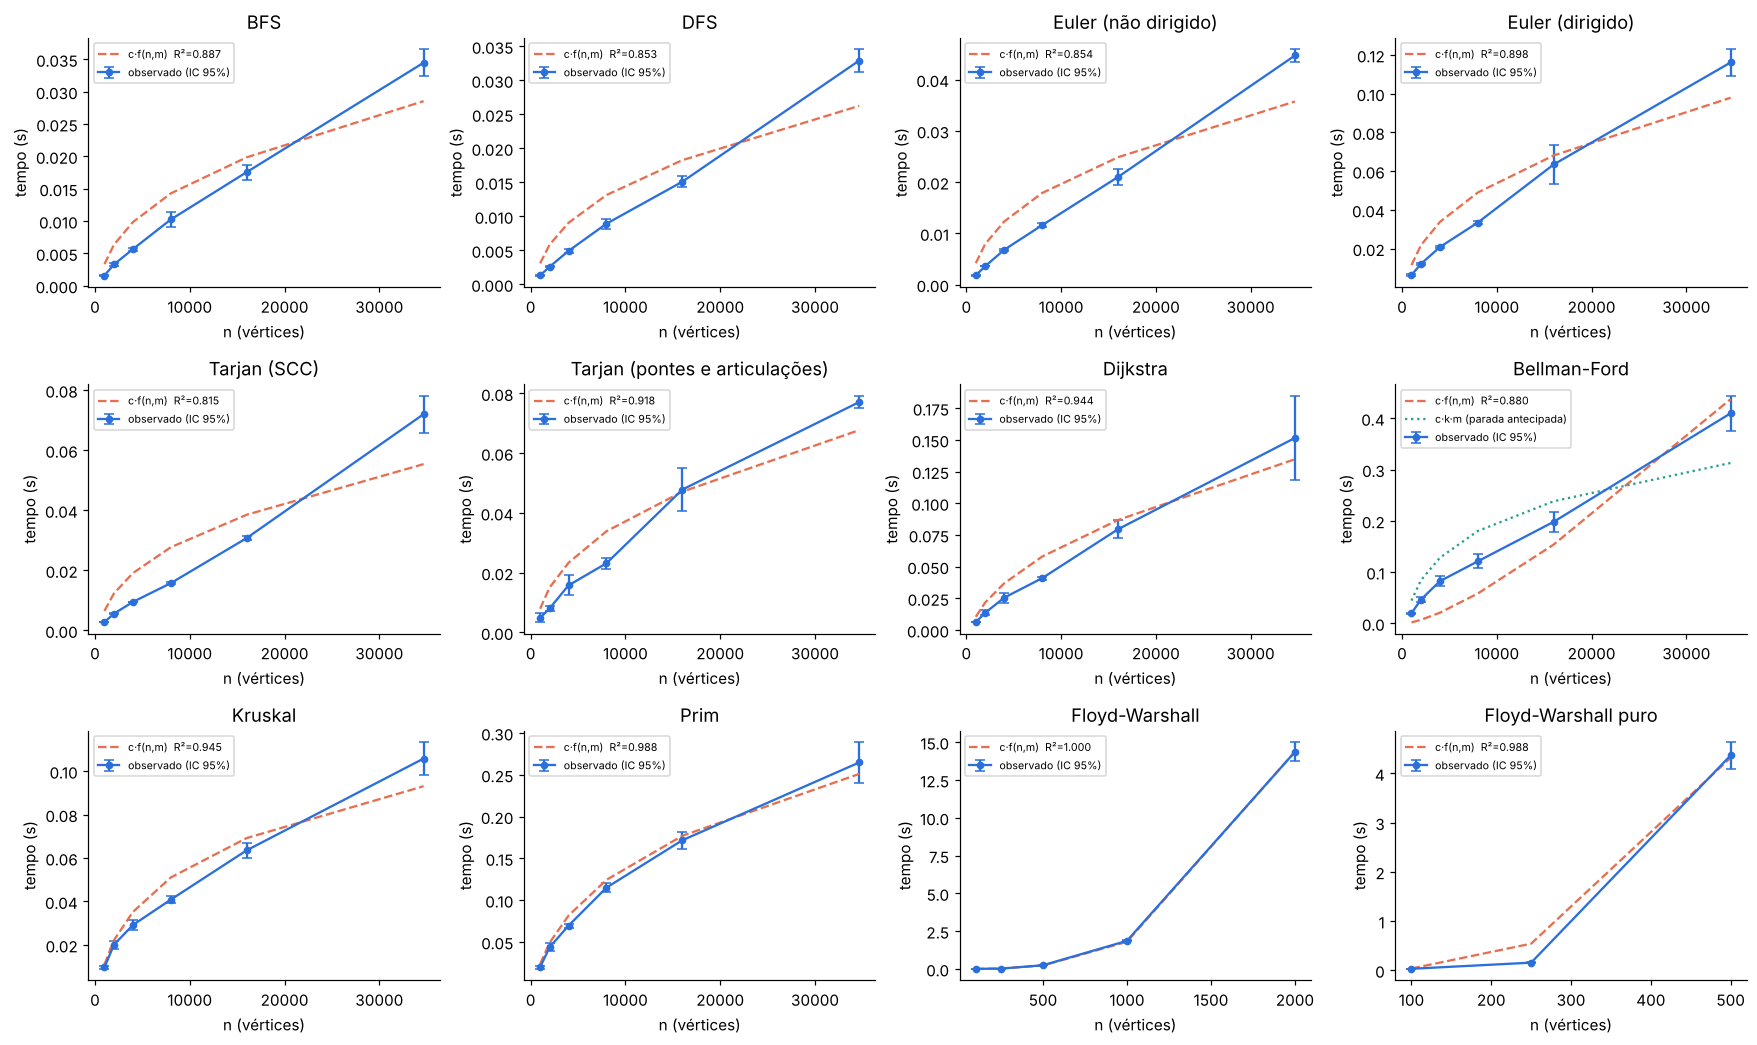

In [16]:
F.escala(esc);

**Por que a curva c·(n + m) se curva?** Os subgrafos são coletados por BFS e começam pelo núcleo denso da rede, então a razão m/n cai de ~17 (n = 1.000) para ~3,6 (grafo completo). Uma única constante para n + m supõe que visitar um vértice custa o mesmo que percorrer uma aresta; em Python o custo por vértice (dicionários, filas) é bem maior. Ajustando custos separados, t ≈ a·n + b·m, o R² sobe para ~0,99 nos algoritmos lineares — compatível com O(n + m).

In [17]:
lin = esc[~esc["algoritmo"].str.startswith("Floyd-Warshall")]
mn = lin.groupby("n")["m"].first()
print("razão m/n por tamanho:", (mn / mn.index).round(1).tolist())
ajuste_nm = pd.DataFrame({a: Me.ajustar_n_m(g["media_s"], g["n"], g["m"]) for a, g in lin.groupby("algoritmo", sort=False)}).T
salvar_tabela(ajuste_nm, "04_ajuste_n_m", "Ajuste do tempo a $a \\cdot n + b \\cdot m$ (custos por vértice e por aresta) e $R^2$.")

razão m/n por tamanho: [17.5, 16.6, 12.6, 8.9, 5.9, 3.6]


,a_por_vertice,b_por_aresta,r2
BFS,8.194646e-07,4.880937e-08,0.999887
DFS,8.594730e-07,2.310665e-08,0.998533
Euler (não dirigido),1.170429e-06,3.139399e-08,0.999348
Euler (dirigido),2.648608e-06,2.008127e-07,0.998945
Tarjan (SCC),2.063143e-06,-2.593807e-09,0.997110
Tarjan (pontes e articulações),1.587713e-06,1.894727e-07,0.991287
Dijkstra,3.702626e-06,1.915658e-07,0.999153
Bellman-Ford,9.309357e-06,6.652367e-07,0.996418
Kruskal,1.483900e-06,4.345593e-07,0.997668
Prim,3.469918e-06,1.185161e-06,0.998066


**Leitura.** O R² do ajuste mostra quão bem cada curva teórica descreve o tempo medido. No Bellman-Ford, a implementação para quando uma rodada não altera nenhuma distância; no grafo real isso ocorre após poucas rodadas (tabela 04), em vez das n − 1 do pior caso, e o custo efetivo fica O(k·m). Compare o R² de c·n·m com o de c·k·m na tabela de ajuste.

## 5. Parte III – (1) Small-world (Apêndice A)

Critério do enunciado: $L(G) \approx L_{aleatório}$ e $C(G) \gg C_{aleatório}$. Aleatório = $G(n, m)$ (gerador próprio) com o mesmo $n$ e $m$ da maior componente; média de 5 grafos, $L$ estimado com 300 BFS por grafo. Sem bibliotecas prontas. O índice $\sigma = (C/C_{al})/(L/L_{al})$ entra como complemento.

In [18]:
sw = M.small_world(adj_lcc, reps=5, fontes=300, seed=SEED)
salvar_tabela(pd.Series(sw, name="valor").to_frame(), "05_small_world",
              "Small-world: G13 (maior componente) contra grafos aleatórios G(n,m) equivalentes.")
print(f"C(G)/C_al = {sw['C(G)/C_aleatorio']:.1f}   L(G)/L_al = {sw['L(G)/L_aleatorio']:.2f}   sigma = {sw['sigma']:.1f}")

C(G)/C_al = 864.6   L(G)/L_al = 0.71   sigma = 1225.3


**Nulo que preserva os graus.** O $G(n,m)$ não tem hubs, e hubs sozinhos já mudam $C$ e $L$. Para separar esse efeito, comparamos também com grafos aleatorizados por trocas duplas de arestas (Maslov e Sneppen, 2002), que mantêm o grau de cada vértice (3 trocas por aresta, 3 repetições).

C(G)/C_graus = 4.28   L(G)/L_graus = 1.05   sigma_graus = 4.08


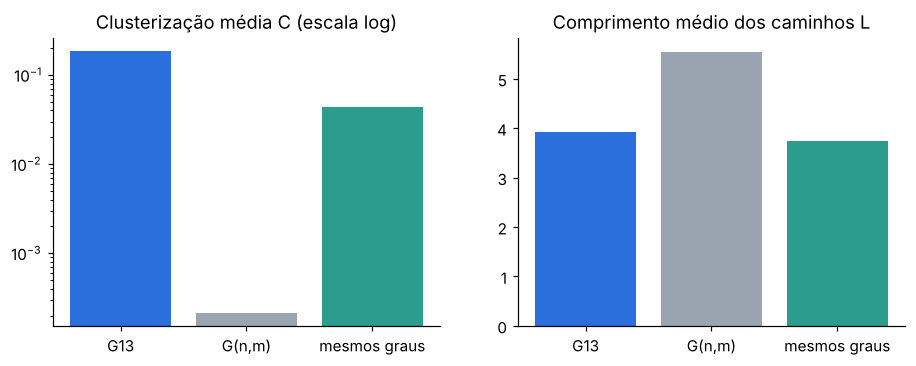

In [19]:
swg = M.small_world_graus(adj_lcc, reps=3, fontes=300, seed=SEED)
salvar_tabela(pd.Series(swg, name="valor").to_frame(), "05_small_world_graus",
              "Small-world: G13 contra grafos aleatórios com a mesma sequência de graus.")
F.small_world(sw, swg)
print(f"C(G)/C_graus = {swg['C(G)/C_graus']:.2f}   L(G)/L_graus = {swg['L(G)/L_graus']:.2f}   sigma_graus = {swg['sigma_graus']:.2f}")

## 6. Parte III – (2) Lei de potência (Apêndice B)

Modelo: $P(k) \sim C\,k^{-\gamma}$, $\gamma > 1$; em log-log, $\log P(k) = -\gamma \log k + \log C$ é uma reta.
$\gamma$ por regressão linear em $\log P(k)$ × $\log k$ (método do enunciado), com $P(k)$ bruto e com histograma de bins logarítmicos (menos ruído na cauda); pela CCDF; e por máxima verossimilhança (Clauset et al., 2009).

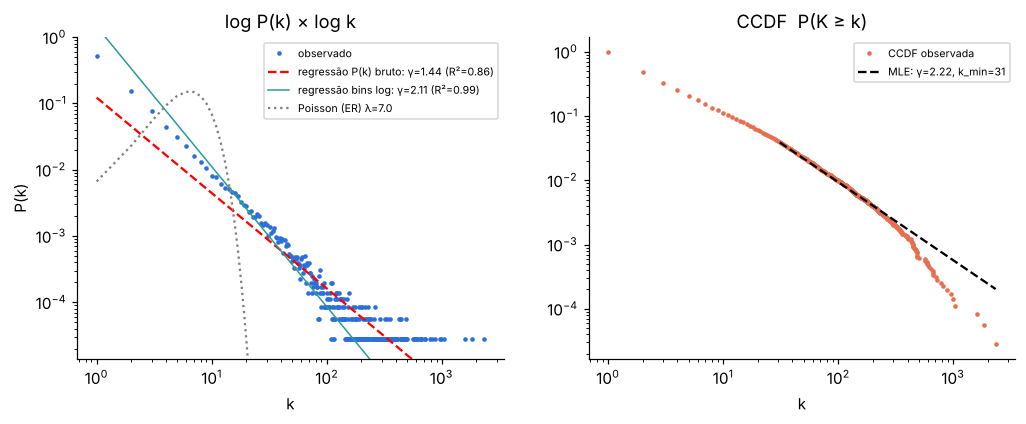

In [20]:
pl = M.lei_potencia(adj)
salvar_tabela(pd.Series(pl, name="valor").to_frame(), "06_lei_potencia", "Ajustes de lei de potência à distribuição de graus.")
F.lei_potencia(adj, pl, rg["grau_medio"]);

## 7. Parte III – (3) Robustez (Apêndice C)

Maior componente conexa; $n = |V|$, $r = \lceil 0{,}05 \times n \rceil$. Métricas: **A** $S$ (maior componente / $n$ original); **B** $c$ (nº de componentes); **C** caminho médio na maior componente (200 BFS); **D** fração de isolados.
Aleatória: 30 repetições. Ataque com ranking fixo por **grau**, por **betweenness** (Brandes próprio, 1.000 fontes sorteadas) e por **PageRank** (próprio, no grafo dirigido ponderado por nº de posts).

In [21]:
t0 = time.perf_counter()
btw = Ce.betweenness_brandes(adj_lcc, fontes=1000, seed=SEED)
print(f"Brandes (1000 fontes): {time.perf_counter() - t0:.0f} s")
r_ = R.r_remover(n_)
pesos = {(u, v): d["count"] for u, v, d in G_dir.edges(data=True)}
pr = Ce.pagerank(succ, pesos)          # implementação própria (iteração de potência)
pr_lcc = {u: pr[u] for u in adj_lcc}
if CONFERIR_IGRAPH:
    btw_ig = dict(zip(g_lcc.vs["_nx_name"], g_lcc.betweenness(directed=False)))
    top_p = set(sorted(btw, key=btw.get)[-r_:]); top_i = set(sorted(btw_ig, key=btw_ig.get)[-r_:])
    print(f"Top {r_} por betweenness: {len(top_p & top_i) / r_:.1%} em comum com o valor exato do igraph")

Brandes (1000 fontes): 147 s


Top 1734 por betweenness: 84.9% em comum com o valor exato do igraph


S_rand = 0.924  S_cent: grau 0.366 | btw 0.364 | PR 0.428
c_rand = 869.2  c_cent: grau 17458 | btw 17799 | PR 16176


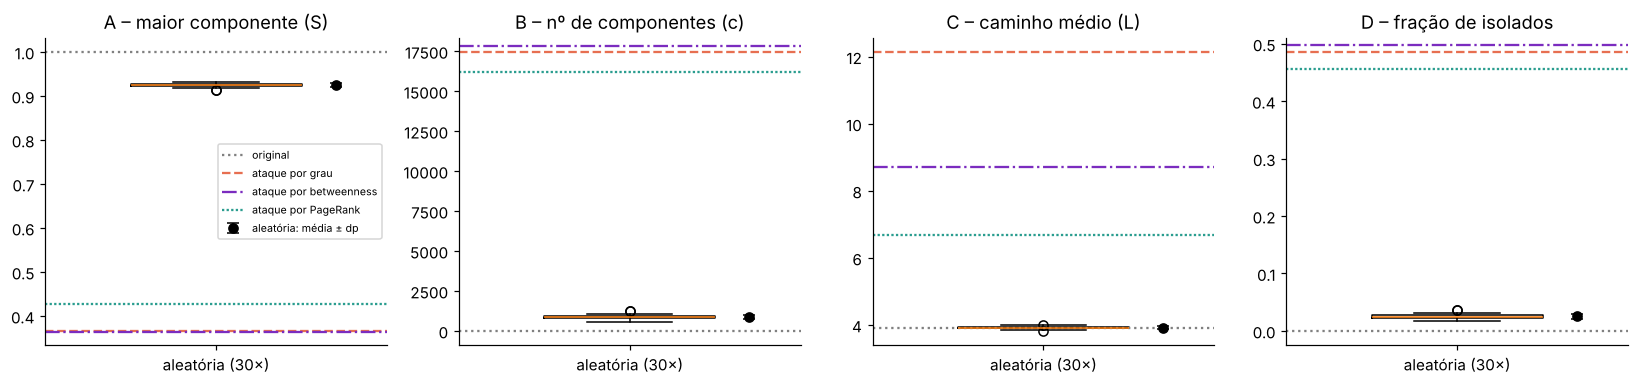

In [22]:
orig = R.metricas(adj_lcc, n_, fontes=200, seed=SEED)
aleat = pd.DataFrame(R.remocao_aleatoria(adj_lcc, reps=30, seed=SEED))
at_grau = R.ataque_direcionado(adj_lcc, dict(G_lcc.degree), seed=SEED)
at_btw = R.ataque_direcionado(adj_lcc, btw, seed=SEED)
at_pr = R.ataque_direcionado(adj_lcc, pr_lcc, seed=SEED)
rob = pd.DataFrame({"original": orig, "aleatória (média)": aleat.mean(), "aleatória (desvio)": aleat.std(),
                    "ataque por grau": at_grau, "ataque por betweenness": at_btw, "ataque por PageRank": at_pr}).T
rob.insert(0, "r removidos", [0, r_, r_, r_, r_, r_])
salvar_tabela(rob, "07_robustez", "Robustez: métricas A–D após remover 5\\% dos vértices da maior componente.")
F.robustez(orig, aleat, {"ataque por grau": at_grau, "ataque por betweenness": at_btw, "ataque por PageRank": at_pr})
print(f"S_rand = {aleat['A_S'].mean():.3f}  S_cent: grau {at_grau['A_S']:.3f} | btw {at_btw['A_S']:.3f} | PR {at_pr['A_S']:.3f}")
print(f"c_rand = {aleat['B_c'].mean():.1f}  c_cent: grau {at_grau['B_c']} | btw {at_btw['B_c']} | PR {at_pr['B_c']}")

## 8. Parte III – (4) Descobertas

In [23]:
salvar_tabela(An.tabela_hubs(G_dir, btw, pr), "08_hubs", "Os 10 subreddits mais centrais por métrica.")
salvar_tabela(An.perfil_hubs(df, G_dir, G_und, pr, btw), "08_perfil_hubs",
              "Perfil dos 10 subreddits de maior grau: direção, centralidade, reciprocidade e links negativos.")

,grau,entrada,saída,PageRank,betweenness,recíproco,neg. enviados,neg. recebidos
subreddit,,,,,,,,
askreddit,2336,2161,363,0.016361,7.073198e+07,0.080479,0.148729,0.121708
iama,1839,1646,384,0.013299,5.637904e+07,0.103861,0.025402,0.048998
subredditdrama,1598,454,1350,0.001530,4.265281e+07,0.128911,0.308039,0.176638
writingprompts,1043,717,426,0.003923,2.200325e+07,0.095877,0.168131,0.041365
outoftheloop,986,592,507,0.002343,2.531909e+07,0.114604,0.070480,0.078313
pics,956,953,4,0.006663,1.575160e+07,0.001046,0.000000,0.130982
videos,881,879,3,0.008445,2.210641e+07,0.001135,0.000000,0.152494
todayilearned,816,816,0,0.004652,1.228176e+07,0.000000,0.000000,0.152678
funny,783,757,40,0.003900,1.155743e+07,0.017880,0.090909,0.148583


In [24]:
salvar_tabela(An.tabela_negativos(df), "08_links_negativos", "Subreddits que mais enviam e recebem links negativos.")
neg = df[df.sign == -1]
recip = sum(1 for u in succ for v in succ[u] if u in set(succ[v])) / G_dir.number_of_edges()
conc = neg.src.value_counts().head(int(0.01 * neg.src.nunique())).sum() / len(neg)
print(f"Reciprocidade (arestas dirigidas com volta): {recip:.3f}")
print(f"Maior SCC: {len(scc[0])} vértices ({len(scc[0]) / G_dir.number_of_nodes():.1%}) × maior componente fraca: {len(wcc[0])}")
print(f"1% dos subreddits que mais enviam links negativos respondem por {conc:.1%} desses links")

Reciprocidade (arestas dirigidas com volta): 0.196
Maior SCC: 11564 vértices (32.3%) × maior componente fraca: 34671
1% dos subreddits que mais enviam links negativos respondem por 39.0% desses links


*(A interpretação da descoberta mais interessante fica no relatório; os números acima e as tabelas 08 dão a base.)*

## 9. EXTRA – Modelos clássicos (geradores próprios)

In [25]:
modelos = An.gerar_modelos(adj_lcc)
salvar_tabela(An.tabela_modelos(modelos), "09_modelos_classicos",
              "G13 comparado a Erdős–Rényi, Barabási–Albert e Watts–Strogatz com o mesmo n e m aproximado.")

,n,m,grau máx,C médio,L,γ (bins log),R² (bins log),γ (MLE)
modelo,,,,,,,,
G13 (maior componente),34671,123570,2336,0.186170,3.960218,2.109955,0.991668,2.216206
"Erdős–Rényi G(n,m)",34671,123570,22,0.000165,5.522228,1.459052,0.195126,2.918330
Barabási–Albert (m=4),34671,138668,620,0.002345,4.270465,2.873236,0.990064,2.877383
"Watts–Strogatz (k=8, p=0,1)",34671,138684,12,0.473073,8.069887,-5.028470,0.360794,5.708763


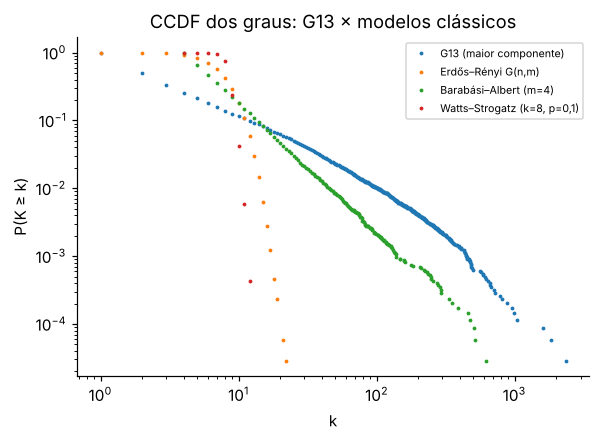

In [26]:
F.modelos_ccdf(modelos);

O γ estimado para Erdős–Rényi e Watts–Strogatz não tem significado físico (essas distribuições não são lei de potência); o R² baixo confirma.

## 10. Valores citados no relatório (`resultados/valores.tex`)

In [27]:
from src.relatorio import escrever_macros
t_med = tempos["media_s"]
valores = {
    "matricula": "224216276", "grafoID": G_ID,
    "postsTotal": len(df), "nVertices": rg["n"], "nArestas": rg["m"], "nArestasDir": G_dir.number_of_edges(),
    "grauMax": rg["grau_max"], "grauMedio": rg["grau_medio"], "densidade": rg["densidade"],
    "nComponentes": len(comps), "nLCC": n_, "mLCC": m_, "fracLCC": pct(n_ / rg["n"]),
    "diametro": dist["diametro"], "raio": dist["raio"], "caminhoMedio": dist["caminho_medio"],
    "clustMedio": clust[0], "transitividade": clust[1], "nTriangulos": clust[2],
    "linksNeg": int((df.sign == -1).sum()), "fracNeg": pct((df.sign == -1).mean()),
    "nSCC": len(scc), "maiorSCC": len(scc[0]), "fracSCC": pct(len(scc[0]) / G_dir.number_of_nodes()),
    "nPontes": len(pontes), "nArticulacoes": len(artic), "pesoAGM": peso_k,
    "iterBFmin": min(iters_bf), "iterBFmax": max(iters_bf),
    "tBFS": t_med["BFS"] * 1e3, "tDijkstra": t_med["Dijkstra"] * 1e3, "tBF": t_med["Bellman-Ford"] * 1e3,
    "tFWmil": t_med["Floyd-Warshall (n=1000)"], "tFWpuroQuinhentos": t_med["Floyd-Warshall puro (n=500)"],
    "tFWQuinhentos": t_med["Floyd-Warshall (n=500)"],
    "razaoC": sw["C(G)/C_aleatorio"], "razaoL": sw["L(G)/L_aleatorio"], "sigmaER": sw["sigma"],
    "Caleat": sw["C_aleatorio"], "Laleat": sw["L_aleatorio"],
    "razaoCgraus": swg["C(G)/C_graus"], "razaoLgraus": swg["L(G)/L_graus"], "sigmaGraus": swg["sigma_graus"],
    "Cgraus": swg["C_graus"], "Lgraus": swg["L_graus"],
    "gammaBruto": pl["gamma_pk"], "rBruto": pl["r2_pk"], "gammaBins": pl["gamma_pk_bins_log"],
    "rBins": pl["r2_pk_bins_log"], "gammaCCDF": pl["gamma_ccdf"], "gammaMLE": pl["gamma_mle"], "kminMLE": pl["kmin_mle"],
    "rRemover": r_, "Srand": aleat["A_S"].mean(), "SrandDP": aleat["A_S"].std(), "crand": aleat["B_c"].mean(),
    "Sgrau": at_grau["A_S"], "cgrau": at_grau["B_c"], "Lgrau": at_grau["C_L"], "isoGrau": pct(at_grau["D_isolados"]),
    "Sbtw": at_btw["A_S"], "cbtw": at_btw["B_c"], "Lbtw": at_btw["C_L"],
    "Spr": at_pr["A_S"], "cpr": at_pr["B_c"], "Lpr": at_pr["C_L"],
    "Lorig": orig["C_L"], "Lrand": aleat["C_L"].mean(), "isoRand": pct(aleat["D_isolados"].mean()),
    "reciprocidade": pct(recip), "concNeg": pct(conc),
    "topIndegree": max(dict(G_dir.in_degree).items(), key=lambda x: x[1])[0],
    "topNeg": neg.src.value_counts().index[0],
    "nucleos": os.cpu_count(), "tDist": round(t_dist),
}
escrever_macros(valores)
print(len(valores), "macros em resultados/valores.tex")

75 macros em resultados/valores.tex


## 11. Arquivos gerados

In [28]:
print("Figuras:", sorted(p.name for p in Path("figuras").glob("*.pdf")))
print("Tabelas:", sorted(p.name for p in Path("resultados").glob("*.tex")))

Figuras: ['01_original_tempo_sinal.pdf', '03_distribuicao_graus.pdf', '03b_visualizacao.pdf', '04_complexidade_observada.pdf', '05_small_world.pdf', '06_lei_potencia.pdf', '07_robustez.pdf', '09_modelos_ccdf.pdf']
Tabelas: ['01_dados_originais.tex', '02_tratamentos.tex', '03_parte1_medidas.tex', '03_tamanho_componentes.tex', '04_ajuste_complexidade.tex', '04_ajuste_n_m.tex', '04_resultados_algoritmos.tex', '04_tempos_execucao.tex', '05_small_world.tex', '05_small_world_graus.tex', '06_lei_potencia.tex', '07_robustez.tex', '08_hubs.tex', '08_links_negativos.tex', '08_perfil_hubs.tex', '09_modelos_classicos.tex', 'valores.tex']
